In [1]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 37.6 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2━━━━━━━━━━━━━━━━━━━━━━━ 1/3 [typer]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [roboflow]2/3 [roboflow]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 10.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [27]:
import os
import shutil
import json
import time
import random
import numpy              as     np
import pandas             as     pd
import matplotlib.pyplot  as     plt
import matplotlib.patches as patches
from PIL                import Image
from roboflow           import Roboflow
from datetime           import datetime
from ultralytics        import YOLO
from kaggle_secrets import UserSecretsClient

# Download Dataset From Roboflow

In [4]:
API_KEY = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=API_KEY)
project = rf.workspace("ay7agaa").project("road-damage-l1ju7-jd0gc")
version = project.version(1)          
dataset = version.download("yolov8", location="dataset")

print("completed successfully", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to dataset in yolov8:: 100%|██████████| 13519/13519 [00:01<00:00, 9053.37it/s] 


completed successfully /kaggle/working/dataset


# Paths

In [5]:
DATA_YAML          = "/kaggle/working/dataset/data.yaml"       
EXPERIMENTS_DIR    = "/kaggle/working/experiments"        
OUTPUTS_DIR        = "/kaggle/working/outputs"
RESULTS_JSON       = "/kaggle/working/outputs/results.json"  
PLOTS_DIR          = "/kaggle/working/outputs/plots"           
VAL_IMAGES_DIR     = "/kaggle/working/dataset/valid/images"    
VAL_LABELS_DIR     = "/kaggle/working/dataset/valid/labels"    
PREDICTIONS_DIR    = "/kaggle/working/outputs/predictions"   
IOU_THRESHOLD      = 0.5    
NUM_IMAGES_TO_SHOW = 9 

# Models

In [6]:
MODELS = ["yolov8s.pt", "yolo11s.pt", "yolo26s.pt"]

# Hyperprameters

In [7]:
EPOCHS = 50
BATCH_SIZE = 16
IMAGE_SIZE = 640
LEARNING_RATE = 0.01
OPTIMIZER = "auto"      # SGD / Adam / AdamW 
SEED = 42

In [8]:
def train_one_model(weights_name: str) -> dict:
    model_name = weights_name.replace(".pt", "")
    run_name = f"{model_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
 
    print(f"\n=== Start training {model_name} ===")
 
    model = YOLO(weights_name)
    model.train(
        data=DATA_YAML,
        epochs=EPOCHS,
        batch=BATCH_SIZE,
        imgsz=IMAGE_SIZE,
        lr0=LEARNING_RATE,
        optimizer=OPTIMIZER,
        seed=SEED,
        project=EXPERIMENTS_DIR,
        name=run_name,
    )
 
    best_weights_path = os.path.join(EXPERIMENTS_DIR, run_name, "weights", "best.pt")

    best_model = YOLO(best_weights_path)
    metrics = best_model.val(data=DATA_YAML)
 
    map50 = metrics.box.map50
    map50_95 = metrics.box.map
    precision = metrics.box.mp
    recall = metrics.box.mr
 
    model_size_mb = os.path.getsize(best_weights_path) / (1024 * 1024)
    dummy_image = "dataset/valid/images"  
    sample_images = os.listdir(dummy_image) if os.path.exists(dummy_image) else []
    fps = None
    avg_inference_ms = None
    if sample_images:
        sample_path = os.path.join(dummy_image, sample_images[0])
        # warm-up run
        best_model.predict(sample_path, verbose=False)
        start = time.time()
        n_runs = 20
        for _ in range(n_runs):
            best_model.predict(sample_path, verbose=False)
        elapsed = time.time() - start
        avg_inference_ms = (elapsed / n_runs) * 1000
        fps = 1000 / avg_inference_ms
 
    result = {
        "model_name": model_name,
        "best_weights_path": best_weights_path,
        "mAP50": round(map50, 4),
        "mAP50-95": round(map50_95, 4),
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "model_size_mb": round(model_size_mb, 2),
        "avg_inference_ms": round(avg_inference_ms, 2) if avg_inference_ms else None,
        "fps": round(fps, 2) if fps else None,
    }
 
    print(f"model name: {model_name} | best weights path: {best_weights_path}")
    print(
        f"mAP50={result['mAP50']} | mAP50-95={result['mAP50-95']} | "
        f"Precision={result['precision']} | Recall={result['recall']} | "
        f"Size={result['model_size_mb']}MB | FPS={result['fps']}"
    )
    return result

In [9]:
def train_all_models():
    results = []
    for weights_name in MODELS:
        result = train_one_model(weights_name)
        results.append(result)
    return results

In [10]:
def print_comparison_table(results: list):
    print("\n=== Comparison Table ===")
    header = f"{'Model':<10}{'mAP50':<10}{'mAP50-95':<12}{'Precision':<12}{'Recall':<10}{'Size(MB)':<10}{'FPS':<10}"
    print(header)
    print("-" * len(header))
    for r in results:
        print(
            f"{r['model_name']:<10}{r['mAP50']:<10}{r['mAP50-95']:<12}"
            f"{r['precision']:<12}{r['recall']:<10}{r['model_size_mb']:<10}{r['fps']:<10}"
        )
    best = max(results, key=lambda r: r["mAP50-95"])
    print(f"\nBest model for deployment (highest mAP50-95): {best['model_name']}")
    print(f"Weights path: {best['best_weights_path']}")

In [11]:
def save_results(results: list):
    os.makedirs(os.path.dirname(RESULTS_JSON), exist_ok=True)
    with open(RESULTS_JSON, "w", encoding="utf-8") as f:
        json.dump(results, f, indent=2, ensure_ascii=False)
    print(f"\nsaved result: {RESULTS_JSON}")

In [12]:
all_results = train_all_models()
print_comparison_table(all_results)
save_results(all_results)


=== Start training yolov8s ===
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_20261028_171858,

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/50      4.34G      1.918      2.554      1.888         60        640: 100% ━━━━━━━━━━━━ 308/308 5.5it/s 56.4s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 4.1it/s 8.7s0.3s
                   all       1142       3570      0.262      0.126     0.0955     0.0342

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      4.35G      1.919      2.514      1.886         81        640: 100% ━━━━━━━━━━━━ 308/308 5.5it/s 55.7s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 4.1it/s 8.8s0.3s
                   all       1142       3570       0.51      0.168      0.168     0.0799

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      4.35G      1.872      2.481      1.873         78        640: 100% ━━━━━━━━━━━━ 308/308 5.5it/s 55.7s0.2ss
                 Class     Ima

# Evaluate Models

In [14]:
def load_results() -> list:
    if not os.path.exists(RESULTS_JSON):
        raise FileNotFoundError(
            f"No Found File '{RESULTS_JSON}'. "
        )
    with open(RESULTS_JSON, "r", encoding="utf-8") as f:
        return json.load(f)

In [15]:
def print_comparison_table(results: list):
    print("\n=== Comparison Table ===")
    header = f"{'Model':<10}{'mAP50':<10}{'mAP50-95':<12}{'Precision':<12}{'Recall':<10}{'Size(MB)':<10}{'FPS':<10}"
    print(header)
    print("-" * len(header))
    for r in results:
        print(
            f"{r['model_name']:<10}{r['mAP50']:<10}{r['mAP50-95']:<12}"
            f"{r['precision']:<12}{r['recall']:<10}{r['model_size_mb']:<10}{r['fps']:<10}"
        )
    best = max(results, key=lambda r: r["mAP50-95"])
    print(f"\nBest model (highest mAP50-95): {best['model_name']}")

In [16]:
def _bar_plot(results: list, metric_key: str, title: str, ylabel: str, filename: str):
    names = [r["model_name"] for r in results]
    values = [r[metric_key] for r in results]
 
    plt.figure(figsize=(6, 4))
    bars = plt.bar(names, values, color=["#4C72B0", "#55A868", "#C44E52"])
    plt.title(title)
    plt.ylabel(ylabel)
    plt.xlabel("Model")
    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            str(value),
            ha="center",
            va="bottom",
        )
 
    plt.tight_layout()
    os.makedirs(PLOTS_DIR, exist_ok=True)
    save_path = os.path.join(PLOTS_DIR, filename)
    plt.savefig(save_path)
    plt.close()
    print(f"Saved Plots: {save_path}")

In [17]:
def plot_all_comparisons(results: list):
    _bar_plot(results, "mAP50", "mAP50 Comparison", "mAP50", "map50.png")
    _bar_plot(results, "mAP50-95", "mAP50-95 Comparison", "mAP50-95", "map50_95.png")
    _bar_plot(results, "precision", "Precision Comparison", "Precision", "precision.png")
    _bar_plot(results, "recall", "Recall Comparison", "Recall", "recall.png")
    _bar_plot(results, "model_size_mb", "Model Size Comparison", "Size (MB)", "model_size.png")
    _bar_plot(results, "fps", "Inference Speed (FPS) Comparison", "FPS", "fps.png")

In [18]:
all_results = load_results()
print_comparison_table(all_results)
plot_all_comparisons(all_results) 


=== Comparison Table ===
Model     mAP50     mAP50-95    Precision   Recall    Size(MB)  FPS       
--------------------------------------------------------------------------
yolov8s   0.4101    0.2399      0.6223      0.3979    21.48     59.3      
yolo11s   0.4284    0.2529      0.6122      0.4217    18.3      55.5      
yolo26s   0.44      0.2578      0.6415      0.4373    19.38     57.97     

Best model (highest mAP50-95): yolo26s
Saved Plots: /kaggle/working/outputs/plots/map50.png
Saved Plots: /kaggle/working/outputs/plots/map50_95.png
Saved Plots: /kaggle/working/outputs/plots/precision.png
Saved Plots: /kaggle/working/outputs/plots/recall.png
Saved Plots: /kaggle/working/outputs/plots/model_size.png
Saved Plots: /kaggle/working/outputs/plots/fps.png


# Visualize

In [20]:
def get_best_model_path() -> str:
    if not os.path.exists(RESULTS_JSON):
        raise FileNotFoundError(
            f"No result in file '{RESULTS_JSON}'"
        )
    with open(RESULTS_JSON, "r", encoding="utf-8") as f:
        results = json.load(f)
    best = max(results, key=lambda r: r["mAP50-95"])
    print(f"Best Model {best['model_name']} ({best['best_weights_path']})")
    return best["best_weights_path"]

In [21]:
def load_ground_truth(label_path: str, img_width: int, img_height: int) -> list:
    boxes = []
    if not os.path.exists(label_path):
        return boxes
 
    with open(label_path, "r") as f:
        for line in f.readlines():
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            class_id, xc, yc, w, h = map(float, parts)
            x1 = (xc - w / 2) * img_width
            y1 = (yc - h / 2) * img_height
            x2 = (xc + w / 2) * img_width
            y2 = (yc + h / 2) * img_height
            boxes.append([int(class_id), x1, y1, x2, y2])
    return boxes

In [22]:
def compute_iou(box1: list, box2: list) -> float:
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
 
    inter_area = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union_area = area1 + area2 - inter_area
 
    return inter_area / union_area if union_area > 0 else 0.0

In [23]:
def match_predictions_to_ground_truth(predictions: list, ground_truths: list) -> list:
    used_gt = set()
    evaluated = []
 
    for pred in predictions:
        pred_class, px1, py1, px2, py2, conf = pred
        best_iou = 0.0
        best_gt_idx = -1
 
        for idx, gt in enumerate(ground_truths):
            if idx in used_gt or gt[0] != pred_class:
                continue
            iou = compute_iou([px1, py1, px2, py2], gt[1:])
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = idx
 
        is_correct = best_iou >= IOU_THRESHOLD
        if is_correct:
            used_gt.add(best_gt_idx)
 
        evaluated.append(
            {
                "class_id": pred_class,
                "box": [px1, py1, px2, py2],
                "confidence": conf,
                "iou": round(best_iou, 2),
                "correct": is_correct,
            }
        )
 
    return evaluated

In [24]:
def draw_image_with_predictions(ax, image_path: str, evaluated_predictions: list, class_names: dict):
    image = Image.open(image_path)
    ax.imshow(image)
    ax.axis("off")
 
    for pred in evaluated_predictions:
        x1, y1, x2, y2 = pred["box"]
        color = "lime" if pred["correct"] else "red"
        label = f"{class_names.get(pred['class_id'], pred['class_id'])} {pred['confidence']:.2f}"
 
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x1, max(y1 - 5, 0), label,
            color="white", fontsize=7,
            bbox=dict(facecolor=color, alpha=0.7, pad=1),
        )
 
    n_correct = sum(1 for p in evaluated_predictions if p["correct"])
    n_total = len(evaluated_predictions)
    ax.set_title(f"{n_correct}/{n_total} correct", fontsize=9)

In [25]:
def visualize():
    model_path = get_best_model_path()
    model = YOLO(model_path)
    class_names = model.names  # dict: {0: "crack", 1: "pothole", ...}
 
    all_images = [f for f in os.listdir(VAL_IMAGES_DIR) if f.lower().endswith((".jpg", ".png", ".jpeg"))]
    if not all_images:
        raise FileNotFoundError(f"Not Found image : '{VAL_IMAGES_DIR}'")
 
    sample_images = random.sample(all_images, min(NUM_IMAGES_TO_SHOW, len(all_images)))
 
    os.makedirs(PREDICTIONS_DIR, exist_ok=True)
 
    total_correct = 0
    total_wrong = 0
 
    grid_size = int(NUM_IMAGES_TO_SHOW ** 0.5) or 1
    fig, axes = plt.subplots(grid_size, grid_size, figsize=(4 * grid_size, 4 * grid_size))
    axes = axes.flatten() if NUM_IMAGES_TO_SHOW > 1 else [axes]
 
    for i, image_name in enumerate(sample_images):
        image_path = os.path.join(VAL_IMAGES_DIR, image_name)
        label_path = os.path.join(VAL_LABELS_DIR, os.path.splitext(image_name)[0] + ".txt")
 
        with Image.open(image_path) as img:
            img_width, img_height = img.size

        results = model.predict(image_path, verbose=False)[0]
        predictions = [
            [int(cls), *box, conf]
            for box, cls, conf in zip(
                results.boxes.xyxy.tolist(),
                results.boxes.cls.tolist(),
                results.boxes.conf.tolist(),
            )
        ]
 
        ground_truths = load_ground_truth(label_path, img_width, img_height)
        evaluated = match_predictions_to_ground_truth(predictions, ground_truths)
        total_correct += sum(1 for p in evaluated if p["correct"])
        total_wrong += sum(1 for p in evaluated if not p["correct"])
 
        draw_image_with_predictions(axes[i], image_path, evaluated, class_names)
    for j in range(len(sample_images), len(axes)):
        axes[j].axis("off")
 
    plt.tight_layout()
    grid_path = os.path.join(PREDICTIONS_DIR, "predictions_grid.png")
    plt.savefig(grid_path, dpi=150)
    plt.show()
    print(f"\nsave in gride: {grid_path}")
 
    print(f"Number of correct   : {total_correct}")
    print(f"Number of incorrect: {total_wrong}")
    total = total_correct + total_wrong
    if total > 0:
        print(f"confidence : {total_correct / total * 100:.1f}%")

Best Model yolo26s (/kaggle/working/experiments/yolo26s_20261028_191119/weights/best.pt)


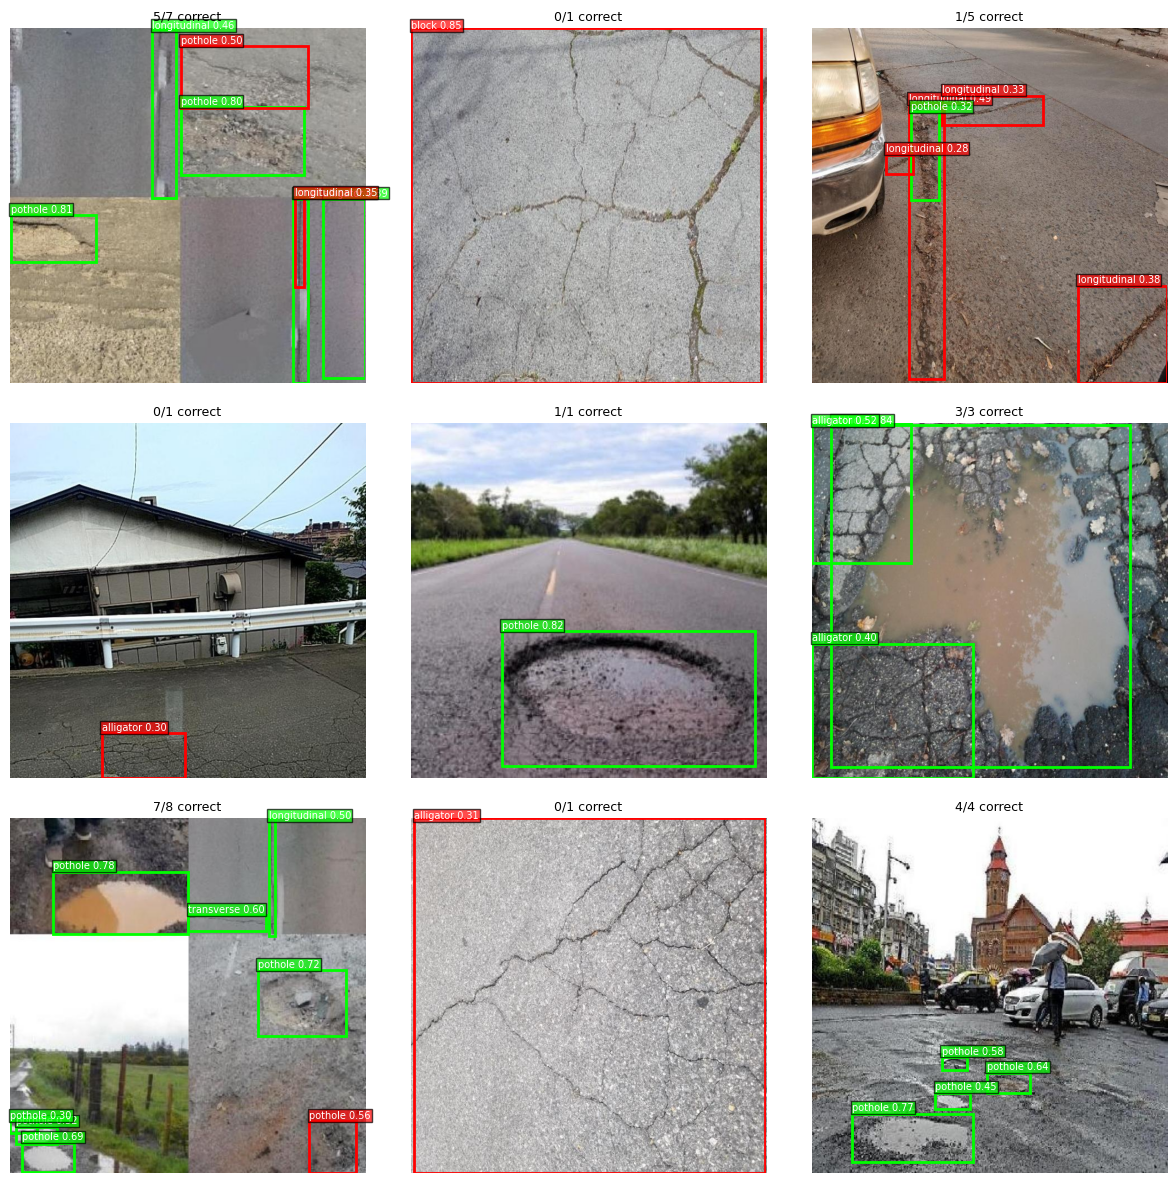


save in gride: /kaggle/working/outputs/predictions/predictions_grid.png
Number of correct   : 21
Number of incorrect: 10
confidence : 67.7%


In [26]:
 visualize()

# Save the Work

In [29]:
source = '/kaggle/working'
destination = '/kaggle/working/working_backup.zip'

if os.path.exists(destination):
    os.remove(destination)

zip_path = shutil.make_archive(
    '/kaggle/working_backup',
    'zip',
    source
)

shutil.move(zip_path, destination)

print("Backup created successfully!")

Backup created successfully!
